# **Step 1 — Import libraries and set reproducibility**
A fixed seed makes the group split and model initialization more reproducible.

In [1]:
import os
import json
import math
import random
import shutil
import zipfile
import time
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import tensorflow as tf
from tensorflow.keras import layers, Model

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix,
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow version:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.20.0
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## Step 2 — Configure the experiment

For the first baseline experiment:

- Image resolution: **96 × 96 grayscale**
- Stroke feature count: **6**
- Maximum sequence length: **512**
- Batch size: **32**
- Initial learning rate: **0.001**
- Maximum epochs: **60**

If a sequence contains more than 512 recorded points, the notebook downsamples the **whole trajectory while preserving each stroke**, instead of simply cutting off the end.

The saved checkpoint uses the requested incremental naming pattern.

In [2]:
# ---------- Experiment configuration ----------

IMG_HEIGHT = 96
IMG_WIDTH = 96
IMG_CHANNELS = 1

# Stroke features:
# [x_norm, y_norm, dx, dy, dt_norm, stroke_start]
SEQ_FEATURES = 6
MAX_SEQ_LEN = 512

BATCH_SIZE = 32
EPOCHS = 60
LEARNING_RATE = 1e-3

MODEL_NAME = "Baybayin_EfficientNetB0_BiLSTM"
MODEL_VERSION = "1.0"

# Dataset paths
UPLOAD_DIR = Path("/content/baya_upload")
OUTER_EXTRACT_DIR = Path("/content/baya_outer_extracted")
EXTRACT_DIR = Path("/content/baya_exports_extracted")
OUTPUT_DIR = Path("/content/baya_model3_output")

# Expected structure of the current BAYA_DATASETS.zip.
EXPECTED_EXPORTS = 14
EXPECTED_CLASSES = 63
EXPECTED_ATTEMPTS_PER_EXPORT = 315
EXPECTED_TOTAL_SAMPLES = EXPECTED_EXPORTS * EXPECTED_ATTEMPTS_PER_EXPORT

for folder in [UPLOAD_DIR, OUTER_EXTRACT_DIR, EXTRACT_DIR, OUTPUT_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

CHECKPOINT_PATH = OUTPUT_DIR / f"{MODEL_NAME}_cp_{MODEL_VERSION}.keras"
FINAL_MODEL_PATH = OUTPUT_DIR / f"{MODEL_NAME}_{MODEL_VERSION}.keras"

print("Checkpoint:", CHECKPOINT_PATH)
print("Final model:", FINAL_MODEL_PATH)
print("Expected inner exports:", EXPECTED_EXPORTS)
print("Expected total samples:", EXPECTED_TOTAL_SAMPLES)

Checkpoint: /content/baya_model3_output/Baybayin_EfficientNetB0_BiLSTM_cp_1.0.keras
Final model: /content/baya_model3_output/Baybayin_EfficientNetB0_BiLSTM_1.0.keras
Expected inner exports: 14
Expected total samples: 4410


## Step 3 — Upload the Dataset


In [3]:
# Google Colab upload: select ONE outer file, BAYA_DATASETS.zip
from google.colab import files

uploaded = files.upload()

zip_names = [
    filename
    for filename in uploaded.keys()
    if filename.lower().endswith(".zip")
]

if len(zip_names) == 0:
    raise ValueError("No ZIP file was uploaded. Please upload BAYA_DATASETS.zip.")

if len(zip_names) > 1:
    raise ValueError(
        "Please upload only ONE outer ZIP file: BAYA_DATASETS.zip. "
        f"Received {len(zip_names)} ZIP files."
    )

uploaded_name = zip_names[0]
OUTER_ZIP_PATH = UPLOAD_DIR / uploaded_name

# Write the uploaded bytes directly to the working folder.
with open(OUTER_ZIP_PATH, "wb") as f:
    f.write(uploaded[uploaded_name])

print("Outer dataset ZIP saved to:")
print(OUTER_ZIP_PATH)
print(f"\nFile size: {OUTER_ZIP_PATH.stat().st_size / (1024**2):.2f} MB")

Saving BAYA_DATASETS.zip to BAYA_DATASETS.zip
Outer dataset ZIP saved to:
/content/baya_upload/BAYA_DATASETS.zip

File size: 35.46 MB


## Step 4 — Extract the outer ZIP, find the 14 nested ZIPs, and extract each export

This performs both extraction levels automatically.

In [4]:
def safe_extract_zip(zip_path: Path, destination: Path):
    # Extract ZIP contents while blocking paths that escape the destination.
    destination.mkdir(parents=True, exist_ok=True)
    destination_resolved = destination.resolve()

    with zipfile.ZipFile(zip_path, "r") as zf:
        for member in zf.infolist():
            target = (destination / member.filename).resolve()
            if destination_resolved not in target.parents and target != destination_resolved:
                raise ValueError(f"Unsafe path inside ZIP: {member.filename}")
        zf.extractall(destination)


# Clean only temporary extraction folders so rerunning this cell
# cannot mix an old extraction with a newly uploaded dataset.
for folder in [OUTER_EXTRACT_DIR, EXTRACT_DIR]:
    if folder.exists():
        shutil.rmtree(folder)
    folder.mkdir(parents=True, exist_ok=True)

# ---------- Level 1: extract BAYA_DATASETS.zip ----------
safe_extract_zip(OUTER_ZIP_PATH, OUTER_EXTRACT_DIR)

# Find all nested dataset ZIP files.
inner_zip_files = sorted(OUTER_EXTRACT_DIR.rglob("*.zip"))

if not inner_zip_files:
    raise FileNotFoundError(
        "No inner BAYA dataset ZIP files were found inside the uploaded outer ZIP."
    )

print(f"Found {len(inner_zip_files)} inner dataset ZIP file(s):")
for z in inner_zip_files:
    print(" -", z.relative_to(OUTER_EXTRACT_DIR))

if len(inner_zip_files) != EXPECTED_EXPORTS:
    print(
        f"\nWARNING: Expected {EXPECTED_EXPORTS} inner exports, "
        f"but found {len(inner_zip_files)}."
    )

# ---------- Level 2: extract each BAYA_dataset_*.zip ----------
for inner_zip in inner_zip_files:
    export_id = inner_zip.stem
    target = EXTRACT_DIR / export_id
    safe_extract_zip(inner_zip, target)

print(f"\nSuccessfully extracted {len(inner_zip_files)} source export(s).")
print("Extracted exports are stored under:")
print(EXTRACT_DIR)

Found 14 inner dataset ZIP file(s):
 - BAYA_DATASETS/BAYA_dataset_2026-09-12T03-51-35-334Z.zip
 - BAYA_DATASETS/BAYA_dataset_2026-09-12T05-43-06-183Z.zip
 - BAYA_DATASETS/BAYA_dataset_2026-09-12T06-40-53-944Z.zip
 - BAYA_DATASETS/BAYA_dataset_2026-09-12T07-47-28-468Z.zip
 - BAYA_DATASETS/BAYA_dataset_2026-09-12T08-33-47-340Z.zip
 - BAYA_DATASETS/BAYA_dataset_2026-09-13T04-12-06-104Z.zip
 - BAYA_DATASETS/BAYA_dataset_2026-09-13T08-10-00-545Z.zip
 - BAYA_DATASETS/BAYA_dataset_2026-09-13T09-02-49-162Z.zip
 - BAYA_DATASETS/BAYA_dataset_2026-09-13T10-34-50-057Z.zip
 - BAYA_DATASETS/BAYA_dataset_2026-09-16T09-50-54-498Z.zip
 - BAYA_DATASETS/BAYA_dataset_2026-09-16T09-54-32-545Z.zip
 - BAYA_DATASETS/BAYA_dataset_2026-09-16T10-03-56-331Z.zip
 - BAYA_DATASETS/BAYA_dataset_2026-09-16T11-55-03-985Z.zip
 - BAYA_DATASETS/BAYA_dataset_2026-09-16T15-13-05-394Z.zip

Successfully extracted 14 source export(s).
Extracted exports are stored under:
/content/baya_exports_extracted


## Step 5 — Read all extracted attempts.json files and build the master index


For every handwriting attempt, this step extracts:

- `source_export = the inner ZIP/export from which the attempt came;
- attemptId;
- targetClass = the class label;
- corresponding PNG path;
- canvas width and height;
- duration;
- recorded strokes.


In [5]:
records = []

export_folders = sorted(
    folder for folder in EXTRACT_DIR.iterdir()
    if folder.is_dir()
)

for export_folder in export_folders:
    attempts_files = list(export_folder.rglob("attempts.json"))

    if len(attempts_files) == 0:
        print("WARNING: No attempts.json found in:", export_folder.name)
        continue

    if len(attempts_files) > 1:
        print(
            f"WARNING: Multiple attempts.json files found in {export_folder.name}. "
            "All will be read."
        )

    for attempts_file in attempts_files:
        export_root = attempts_file.parent

        with open(attempts_file, "r", encoding="utf-8") as f:
            attempts = json.load(f)

        for rec in attempts:
            attempt_id = rec.get("attemptId")
            label = rec.get("targetClass")

            image_uri = rec.get("imageUri")
            if image_uri:
                image_path = export_root / image_uri
            else:
                image_path = export_root / "images" / f"attempt_{attempt_id}.png"

            records.append({
                "source_export": export_folder.name,
                "attempt_id": attempt_id,
                "label": label,
                "image_path": str(image_path),
                "canvas_width": rec.get("canvasWidth"),
                "canvas_height": rec.get("canvasHeight"),
                "duration_ms": rec.get("durationMs"),
                "strokes": rec.get("strokes", []),
            })

df = pd.DataFrame(records)

if df.empty:
    raise ValueError("No handwriting attempts were loaded from the extracted exports.")

print("Total records:", len(df))
print("Unique classes:", df["label"].nunique())
print("Unique source exports:", df["source_export"].nunique())

print("\nRecords per source export:")
display(
    df.groupby("source_export")
      .size()
      .rename("samples")
      .to_frame()
)

display(
    df[["source_export", "attempt_id", "label", "image_path"]].head()
)

Total records: 4410
Unique classes: 63
Unique source exports: 14

Records per source export:


,samples
source_export,
BAYA_dataset_2026-09-12T03-51-35-334Z,315
BAYA_dataset_2026-09-12T05-43-06-183Z,315
BAYA_dataset_2026-09-12T06-40-53-944Z,315
BAYA_dataset_2026-09-12T07-47-28-468Z,315
BAYA_dataset_2026-09-12T08-33-47-340Z,315
BAYA_dataset_2026-09-13T04-12-06-104Z,315
BAYA_dataset_2026-09-13T08-10-00-545Z,315
BAYA_dataset_2026-09-13T09-02-49-162Z,315
BAYA_dataset_2026-09-13T10-34-50-057Z,315


,source_export,attempt_id,label,image_path
0,BAYA_dataset_2026-09-12T03-51-35-334Z,2c200622-c344-46fc-96ac-a6cfa38260b0,a,/content/baya_exports_extracted/BAYA_dataset_2...
1,BAYA_dataset_2026-09-12T03-51-35-334Z,78568eb0-ec63-4fb2-9e39-2266dfd0b261,a,/content/baya_exports_extracted/BAYA_dataset_2...
2,BAYA_dataset_2026-09-12T03-51-35-334Z,17d7330b-0e73-465f-8e8e-816c53dc368e,a,/content/baya_exports_extracted/BAYA_dataset_2...
3,BAYA_dataset_2026-09-12T03-51-35-334Z,c46b7565-c197-42b1-b5cb-1922d0bd1adb,a,/content/baya_exports_extracted/BAYA_dataset_2...
4,BAYA_dataset_2026-09-12T03-51-35-334Z,6bfd3fc2-6f3f-4869-8b2f-163a9c166a60,a,/content/baya_exports_extracted/BAYA_dataset_2...


## Step 6 — Validate the complete combined dataset before training


In [6]:
# Missing labels
missing_labels = df["label"].isna().sum()

# Missing images
df["image_exists"] = df["image_path"].apply(lambda p: Path(p).exists())
missing_images = (~df["image_exists"]).sum()

# Duplicate attempt IDs inside the same export
duplicate_attempts = df.duplicated(["source_export", "attempt_id"]).sum()

def point_count(strokes):
    return sum(len(stroke.get("points", [])) for stroke in strokes)

def stroke_count(strokes):
    return len(strokes)

df["point_count"] = df["strokes"].apply(point_count)
df["stroke_count"] = df["strokes"].apply(stroke_count)

actual_exports = df["source_export"].nunique()
actual_classes = df["label"].nunique()
actual_samples = len(df)

print("========== DATASET VALIDATION ==========")
print("Source exports:", actual_exports, f"(expected {EXPECTED_EXPORTS})")
print("Classes:", actual_classes, f"(expected {EXPECTED_CLASSES})")
print("Total samples:", actual_samples, f"(expected {EXPECTED_TOTAL_SAMPLES})")
print("Missing labels:", missing_labels)
print("Missing images:", missing_images)
print("Duplicate attempts:", duplicate_attempts)

if missing_labels > 0:
    raise ValueError("Dataset contains missing targetClass labels.")

if missing_images > 0:
    missing_preview = df.loc[~df["image_exists"], "image_path"].head(10).tolist()
    raise FileNotFoundError(
        f"Missing {missing_images} image(s). Examples: {missing_preview}"
    )

if duplicate_attempts > 0:
    raise ValueError(
        f"Found {duplicate_attempts} duplicate (source_export, attempt_id) pair(s)."
    )

if actual_exports != EXPECTED_EXPORTS:
    print(f"\nWARNING: Expected {EXPECTED_EXPORTS} exports but found {actual_exports}.")

if actual_classes != EXPECTED_CLASSES:
    print(f"\nWARNING: Expected {EXPECTED_CLASSES} classes but found {actual_classes}.")

if actual_samples != EXPECTED_TOTAL_SAMPLES:
    print(
        f"\nWARNING: Expected {EXPECTED_TOTAL_SAMPLES} total samples "
        f"but found {actual_samples}."
    )

print("\nSamples per export:")
display(
    df.groupby("source_export")
      .size()
      .rename("samples")
      .to_frame()
)

print("\nSamples per class:")
display(
    df["label"]
      .value_counts()
      .sort_index()
      .to_frame("samples")
)

print("\nPoint-count statistics:")
display(
    df["point_count"]
      .describe(percentiles=[0.50, 0.75, 0.90, 0.95, 0.99])
      .to_frame()
)

print("\nStroke-count statistics:")
display(df["stroke_count"].describe().to_frame())

over_limit = (df["point_count"] > MAX_SEQ_LEN).mean() * 100
print(f"Samples longer than MAX_SEQ_LEN={MAX_SEQ_LEN}: {over_limit:.2f}%")

print("\nValidation completed.")

========== DATASET VALIDATION ==========
Source exports: 14 (expected 14)
Classes: 63 (expected 63)
Total samples: 4410 (expected 4410)
Missing labels: 0
Missing images: 0
Duplicate attempts: 0

Samples per export:


,samples
source_export,
BAYA_dataset_2026-09-12T03-51-35-334Z,315
BAYA_dataset_2026-09-12T05-43-06-183Z,315
BAYA_dataset_2026-09-12T06-40-53-944Z,315
BAYA_dataset_2026-09-12T07-47-28-468Z,315
BAYA_dataset_2026-09-12T08-33-47-340Z,315
BAYA_dataset_2026-09-13T04-12-06-104Z,315
BAYA_dataset_2026-09-13T08-10-00-545Z,315
BAYA_dataset_2026-09-13T09-02-49-162Z,315
BAYA_dataset_2026-09-13T10-34-50-057Z,315



Samples per class:


,samples
label,
a,70
b,70
ba,70
be_bi,70
bo_bu,70
...,...
wo_wu,70
y,70
ya,70



Point-count statistics:


,point_count
count,4410.000000
mean,206.356463
std,139.420745
min,21.000000
50%,176.000000
75%,281.000000
90%,392.000000
95%,475.550000
99%,638.910000
max,1170.000000



Stroke-count statistics:


,stroke_count
count,4410.000000
mean,2.853515
std,1.086356
min,1.000000
25%,2.000000
50%,3.000000
75%,4.000000
max,12.000000


Samples longer than MAX_SEQ_LEN=512: 3.56%

Validation completed.


## Step 7 — Visual sanity check

Inspect random examples if the displayed class label matches the handwritten character.

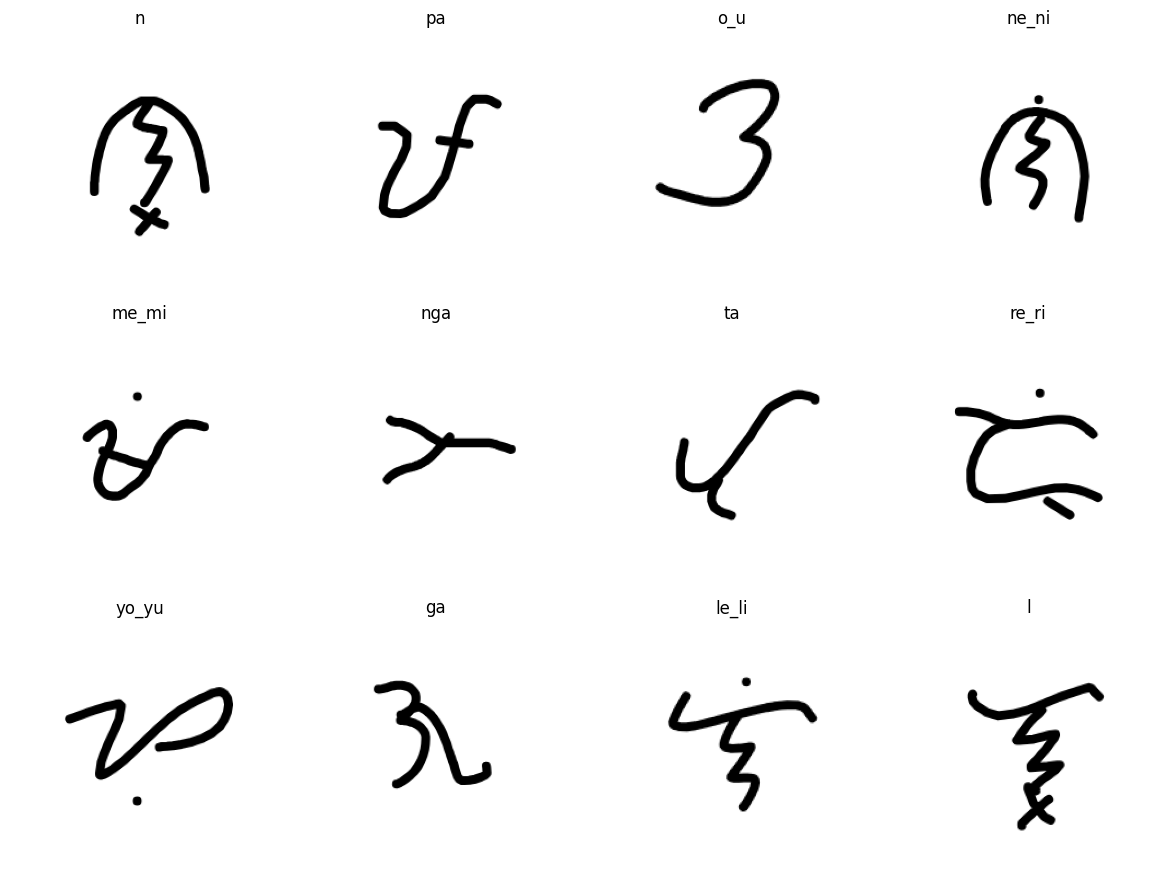

In [7]:
sample_rows = df.sample(min(12, len(df)), random_state=SEED).reset_index(drop=True)

plt.figure(figsize=(12, 9))

for i, row in sample_rows.iterrows():
    img = Image.open(row["image_path"]).convert("RGBA")

    # Composite transparent images onto white.
    bg = Image.new("RGBA", img.size, (255, 255, 255, 255))
    bg.alpha_composite(img)
    gray = bg.convert("L")

    plt.subplot(3, 4, i + 1)
    plt.imshow(gray, cmap="gray")
    plt.title(str(row["label"]))
    plt.axis("off")

plt.tight_layout()
plt.show()

## Step 8 — Create the label mapping

In [8]:
classes = sorted(df["label"].astype(str).unique())
label_to_id = {label: idx for idx, label in enumerate(classes)}
id_to_label = {idx: label for label, idx in label_to_id.items()}

df["label_id"] = df["label"].astype(str).map(label_to_id).astype("int32")

NUM_CLASSES = len(classes)

print("Number of classes:", NUM_CLASSES)
print("First 20 mappings:")
for label in classes[:20]:
    print(f"{label:12s} -> {label_to_id[label]}")

if NUM_CLASSES != 63:
    print(f"\nNOTE: Current combined dataset has {NUM_CLASSES} classes instead of 63.")

Number of classes: 63
First 20 mappings:
a            -> 0
b            -> 1
ba           -> 2
be_bi        -> 3
bo_bu        -> 4
d            -> 5
da_ra        -> 6
de_di        -> 7
do_du        -> 8
e_i          -> 9
g            -> 10
ga           -> 11
ge_gi        -> 12
go_gu        -> 13
h            -> 14
ha           -> 15
he_hi        -> 16
ho_hu        -> 17
k            -> 18
ka           -> 19


## Step 9 — Define position and size-normalized image preprocessing

1. finds the handwriting bounding box;
2. crops around all visible handwriting, including kudlit marks;
3. adds proportional padding;
4. centers the crop on a square background;
5. preserves the character's aspect ratio;
6. resizes the standardized square to **96 × 96**.

Image tensor shape: (96, 96, 1)
Pixel range: 0.0 to 1.0


/tmp/ipykernel_6717/2494837767.py:52: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  standardized = Image.fromarray(square_u8, mode="L").resize(


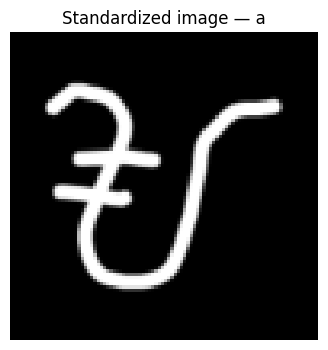

In [9]:
IMAGE_PADDING_RATIO = 0.15
INK_THRESHOLD = 0.08


def load_image_array(image_path):
    # 1. Load and place transparent images on white.
    img = Image.open(image_path).convert("RGBA")
    bg = Image.new("RGBA", img.size, (255, 255, 255, 255))
    bg.alpha_composite(img)

    # 2. Convert to grayscale.
    gray = bg.convert("L")
    arr = np.asarray(gray, dtype=np.float32) / 255.0

    # 3. Convert black handwriting to high-valued ink.
    #    white background -> 0
    #    black handwriting -> 1
    ink = 1.0 - arr

    # 4. Detect all visible handwriting.
    mask = ink > INK_THRESHOLD

    if np.any(mask):
        ys, xs = np.where(mask)

        y0, y1 = int(ys.min()), int(ys.max()) + 1
        x0, x1 = int(xs.min()), int(xs.max()) + 1

        # 5. Crop to the handwriting bounding box.
        crop = ink[y0:y1, x0:x1]

        crop_h, crop_w = crop.shape
        max_dim = max(crop_h, crop_w)

        # 6. Add proportional padding around the character.
        padding = max(2, int(round(max_dim * IMAGE_PADDING_RATIO)))
        square_side = max_dim + 2 * padding

        # 7. Center on a square canvas while preserving aspect ratio.
        square = np.zeros((square_side, square_side), dtype=np.float32)

        top = (square_side - crop_h) // 2
        left = (square_side - crop_w) // 2

        square[top:top + crop_h, left:left + crop_w] = crop
    else:
        # Fallback for an unexpectedly blank image.
        square = ink

    # 8. Resize only after centering / scale normalization.
    square_u8 = np.clip(square * 255.0, 0, 255).astype(np.uint8)
    standardized = Image.fromarray(square_u8, mode="L").resize(
        (IMG_WIDTH, IMG_HEIGHT),
        Image.Resampling.BILINEAR,
    )

    result = np.asarray(standardized, dtype=np.float32) / 255.0

    # H x W x 1
    result = np.expand_dims(result, axis=-1)
    return result.astype(np.float32)


# Quick preprocessing check
test_img = load_image_array(df.iloc[0]["image_path"])

print("Image tensor shape:", test_img.shape)
print("Pixel range:", float(test_img.min()), "to", float(test_img.max()))

plt.figure(figsize=(4, 4))
plt.imshow(test_img[..., 0], cmap="gray")
plt.title(f"Standardized image — {df.iloc[0]['label']}")
plt.axis("off")
plt.show()

## Step 10 — Define position and size-normalized stroke preprocessing BiLSTM

The BiLSTM receives the same six features per time step, but the coordinate normalization is now improved.

| Feature | Meaning |
|---|---|
| `x_shape` | x position relative to the handwriting's own centered bounding square |
| `y_shape` | y position relative to the handwriting's own centered bounding square |
| `dx` | normalized x movement since the previous point in the same stroke |
| `dy` | normalized y movement since the previous point in the same stroke |
| `dt_norm` | elapsed time since the previous recorded point divided by total attempt duration |
| `stroke_start` | 1 for the first point of a stroke, otherwise 0 |
---

1. finds the bounding box of the complete recorded trajectory;
2. finds its center;
3. uses the larger of handwriting width/height as a common scale;
4. adds the same **15% proportional margin** used for the image branch;
5. maps the character into a centered normalized square.

This preserves the handwriting's **aspect ratio** while making its absolute canvas position and overall size much less important.

----
### Stroke boundaries

dx and dy are reset to zero whenever a new stroke starts. A pen lift should not be interpreted as a drawn line between two distant points.

---
### Long sequences

If a sample contains more than 512 points, each stroke is downsampled proportionally across the **whole writing attempt**. The model does not simply discard the end of the trajectory.

Sequence tensor shape: (512, 6)
First 5 time steps:
[[0.11538462 0.22654516 0.         0.         0.         1.        ]
 [0.11538462 0.22654516 0.         0.         0.00139725 0.        ]
 [0.11538462 0.22654516 0.         0.         0.00268512 0.        ]
 [0.11538462 0.22654516 0.         0.         0.00131514 0.        ]
 [0.11538462 0.22654516 0.         0.         0.00610189 0.        ]]


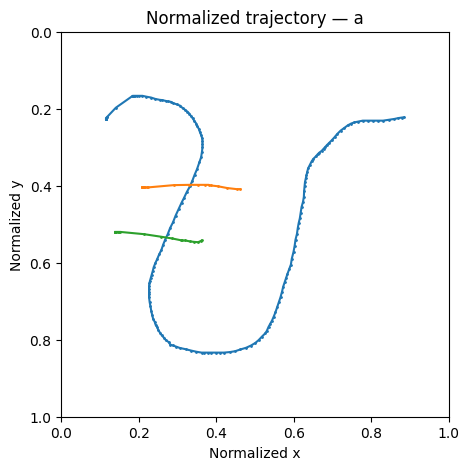

In [10]:
TRAJECTORY_PADDING_RATIO = 0.15


def allocate_points_per_stroke(lengths, max_total):
    n = len(lengths)
    if n == 0:
        return []

    total = sum(lengths)
    if total <= max_total:
        return lengths.copy()

    # Preserve at least 2 points per stroke when possible.
    min_each = 2 if max_total >= 2 * n else 1
    base = np.array([min(min_each, L) for L in lengths], dtype=int)

    remaining = max_total - int(base.sum())
    if remaining <= 0:
        return base.tolist()

    capacity = np.array(
        [max(0, L - b) for L, b in zip(lengths, base)],
        dtype=float,
    )

    if capacity.sum() == 0:
        return base.tolist()

    raw_extra = remaining * capacity / capacity.sum()
    extra = np.floor(raw_extra).astype(int)
    alloc = base + extra

    leftover = max_total - int(alloc.sum())
    if leftover > 0:
        order = np.argsort(-(raw_extra - extra))
        for idx in order:
            if leftover <= 0:
                break
            if alloc[idx] < lengths[idx]:
                alloc[idx] += 1
                leftover -= 1

    return alloc.tolist()


def select_evenly(points, target_count):
    if target_count >= len(points):
        return points

    if target_count <= 1:
        return [points[0]]

    indices = np.linspace(0, len(points) - 1, target_count)
    indices = np.unique(np.round(indices).astype(int))

    if len(indices) < target_count:
        used = set(indices.tolist())
        unused = [i for i in range(len(points)) if i not in used]
        need = target_count - len(indices)
        indices = np.sort(
            np.concatenate([indices, np.asarray(unused[:need], dtype=int)])
        )

    return [points[int(i)] for i in indices[:target_count]]


def get_trajectory_transform(clean_strokes):
    # Use every recorded point to determine the complete handwriting bounds.
    all_points = [
        point
        for stroke in clean_strokes
        for point in stroke.get("points", [])
    ]

    if not all_points:
        return 0.0, 0.0, 1.0

    xs = np.asarray([float(p["x"]) for p in all_points], dtype=np.float32)
    ys = np.asarray([float(p["y"]) for p in all_points], dtype=np.float32)

    min_x, max_x = float(xs.min()), float(xs.max())
    min_y, max_y = float(ys.min()), float(ys.max())

    center_x = (min_x + max_x) / 2.0
    center_y = (min_y + max_y) / 2.0

    width = max_x - min_x
    height = max_y - min_y

    # Use ONE scale for x and y so the character's aspect ratio is preserved.
    handwriting_size = max(width, height, 1e-6)

    # 15% on each side -> multiply the total square scale by 1.30.
    scale = handwriting_size * (1.0 + 2.0 * TRAJECTORY_PADDING_RATIO)

    return center_x, center_y, scale


def build_sequence(row, max_len=MAX_SEQ_LEN):
    strokes = row["strokes"]
    duration = max(float(row["duration_ms"] or 0.0), 1.0)

    clean_strokes = [
        stroke
        for stroke in strokes
        if len(stroke.get("points", [])) > 0
    ]

    if not clean_strokes:
        return np.zeros((max_len, SEQ_FEATURES), dtype=np.float32)

    # Determine a character-relative coordinate system BEFORE downsampling.
    center_x, center_y, scale = get_trajectory_transform(clean_strokes)

    lengths = [len(stroke["points"]) for stroke in clean_strokes]
    allocated = allocate_points_per_stroke(lengths, max_len)

    sampled_strokes = []
    for stroke, n_keep in zip(clean_strokes, allocated):
        sampled_strokes.append(
            select_evenly(stroke["points"], n_keep)
        )

    features = []
    previous_global_t = None

    for stroke_points in sampled_strokes:
        previous_x = None
        previous_y = None

        for j, point in enumerate(stroke_points):
            raw_x = float(point["x"])
            raw_y = float(point["y"])
            t = float(point.get("t", 0.0))

            # Center and scale relative to the handwriting itself.
            x = ((raw_x - center_x) / scale) + 0.5
            y = ((raw_y - center_y) / scale) + 0.5

            stroke_start = 1.0 if j == 0 else 0.0

            if j == 0:
                dx = 0.0
                dy = 0.0
            else:
                dx = x - previous_x
                dy = y - previous_y

            if previous_global_t is None:
                dt_norm = 0.0
            else:
                dt_norm = max(0.0, t - previous_global_t) / duration

            features.append([
                np.clip(x, 0.0, 1.0),
                np.clip(y, 0.0, 1.0),
                dx,
                dy,
                np.clip(dt_norm, 0.0, 1.0),
                stroke_start,
            ])

            previous_x = x
            previous_y = y
            previous_global_t = t

    seq = np.asarray(features, dtype=np.float32)

    # Zero-pad shorter sequences.
    if len(seq) < max_len:
        padding = np.zeros(
            (max_len - len(seq), SEQ_FEATURES),
            dtype=np.float32,
        )
        seq = np.vstack([seq, padding])

    seq = seq[:max_len]
    return seq


# Quick trajectory preprocessing check
test_seq = build_sequence(df.iloc[0])

print("Sequence tensor shape:", test_seq.shape)
print("First 5 time steps:")
print(test_seq[:5])

valid_steps = np.any(test_seq != 0.0, axis=1)
trajectory = test_seq[valid_steps]

plt.figure(figsize=(5, 5))

start_indices = np.where(trajectory[:, 5] == 1.0)[0]

for i, start in enumerate(start_indices):
    end = start_indices[i + 1] if i + 1 < len(start_indices) else len(trajectory)

    stroke = trajectory[start:end]

    plt.plot(
        stroke[:, 0],
        stroke[:, 1],
        marker=".",
        markersize=2
    )

plt.xlim(0, 1)
plt.ylim(1, 0)

plt.xlabel("Normalized x")
plt.ylabel("Normalized y")
plt.title(f"Normalized trajectory — {df.iloc[0]['label']}")
plt.show()

## Step 11 — Split by complete source export: 10 / 2 / 2

Because your current `BAYA_DATASETS.zip` contains **14 complete exports**, this notebook uses:

```
10 exports → Training
 2 exports → Validation
 2 exports → Testing
```

If every export contains 315 attempts, this gives:

```
Training:   3,150 samples
Validation:   630 samples
Testing:      630 samples
```

The split is performed by **whole export**, never by random individual PNG.

This helps prevent repeated attempts from the same collection session from being divided between training and testing.

> Important: `source_export` is a collection-session identifier, not necessarily a person identifier. If the same participant produced multiple ZIP exports, those exports should later be grouped under the same participant before the final thesis evaluation.

In [11]:
groups = sorted(df["source_export"].unique())

if len(groups) < 3:
    raise ValueError(
        f"Need at least 3 source exports for group splitting; found {len(groups)}."
    )

rng = np.random.default_rng(SEED)
shuffled_groups = np.array(groups, dtype=object)
rng.shuffle(shuffled_groups)

# For the current 14-export dataset: exactly 10 train / 2 val / 2 test.
if len(groups) == 14:
    n_test = 2
    n_val = 2
else:
    # General fallback if the dataset changes later.
    n_test = max(1, round(len(groups) * 0.15))
    n_val = max(1, round(len(groups) * 0.15))

    while n_test + n_val >= len(groups):
        if n_val > 1:
            n_val -= 1
        elif n_test > 1:
            n_test -= 1
        else:
            break

test_groups = list(shuffled_groups[:n_test])
val_groups = list(shuffled_groups[n_test:n_test + n_val])
train_groups = list(shuffled_groups[n_test + n_val:])

train_df = df[df["source_export"].isin(train_groups)].reset_index(drop=True)
val_df = df[df["source_export"].isin(val_groups)].reset_index(drop=True)
test_df = df[df["source_export"].isin(test_groups)].reset_index(drop=True)

print("========== GROUP SPLIT ==========")
print(f"TRAIN ({len(train_groups)} exports)")
for g in train_groups:
    print(" -", g)

print(f"\nVALIDATION ({len(val_groups)} exports)")
for g in val_groups:
    print(" -", g)

print(f"\nTEST ({len(test_groups)} exports)")
for g in test_groups:
    print(" -", g)

print("\nSample counts")
print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))
print("Total:", len(train_df) + len(val_df) + len(test_df))

# Verify there is no source-export leakage.
assert set(train_groups).isdisjoint(val_groups)
assert set(train_groups).isdisjoint(test_groups)
assert set(val_groups).isdisjoint(test_groups)

# Check that every split contains all labels.
for name, part in [
    ("train", train_df),
    ("validation", val_df),
    ("test", test_df),
]:
    missing = sorted(set(classes) - set(part["label"].astype(str)))
    print(
        f"{name}: exports={part['source_export'].nunique()}, "
        f"samples={len(part)}, "
        f"classes={part['label'].nunique()}, "
        f"missing={len(missing)}"
    )
    if missing:
        print(" Missing labels:", missing[:20])

========== GROUP SPLIT ==========
TRAIN (10 exports)
 - BAYA_dataset_2026-09-12T03-51-35-334Z
 - BAYA_dataset_2026-09-16T10-03-56-331Z
 - BAYA_dataset_2026-09-16T15-13-05-394Z
 - BAYA_dataset_2026-09-16T09-54-32-545Z
 - BAYA_dataset_2026-09-13T04-12-06-104Z
 - BAYA_dataset_2026-09-12T06-40-53-944Z
 - BAYA_dataset_2026-09-12T08-33-47-340Z
 - BAYA_dataset_2026-09-16T11-55-03-985Z
 - BAYA_dataset_2026-09-12T05-43-06-183Z
 - BAYA_dataset_2026-09-13T10-34-50-057Z

VALIDATION (2 exports)
 - BAYA_dataset_2026-09-16T09-50-54-498Z
 - BAYA_dataset_2026-09-12T07-47-28-468Z

TEST (2 exports)
 - BAYA_dataset_2026-09-13T08-10-00-545Z
 - BAYA_dataset_2026-09-13T09-02-49-162Z

Sample counts
Train: 3150
Validation: 630
Test: 630
Total: 4410
train: exports=10, samples=3150, classes=63, missing=0
validation: exports=2, samples=630, classes=63, missing=0
test: exports=2, samples=630, classes=63, missing=0


## Step 12 — Convert each split into tensors


- `X_img` → shape `(N, 96, 96, 1)`
- `X_seq` → shape `(N, 512, 6)`
- `y` → integer class IDs

In [12]:
def dataframe_to_arrays(part_df, name="dataset"):
    images = []
    sequences = []
    labels = []

    for i, row in part_df.iterrows():
        images.append(load_image_array(row["image_path"]))
        sequences.append(build_sequence(row))
        labels.append(int(row["label_id"]))

        if (i + 1) % 250 == 0:
            print(f"{name}: processed {i + 1}/{len(part_df)}")

    return (
        np.stack(images).astype(np.float32),
        np.stack(sequences).astype(np.float32),
        np.asarray(labels, dtype=np.int32),
    )

Ximg_train, Xseq_train, y_train = dataframe_to_arrays(train_df, "train")
Ximg_val, Xseq_val, y_val = dataframe_to_arrays(val_df, "validation")
Ximg_test, Xseq_test, y_test = dataframe_to_arrays(test_df, "test")

print("\nShapes:")
print("Train image:", Ximg_train.shape)
print("Train sequence:", Xseq_train.shape)
print("Train labels:", y_train.shape)
print("Validation image:", Ximg_val.shape)
print("Test image:", Ximg_test.shape)

/tmp/ipykernel_6717/2494837767.py:52: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  standardized = Image.fromarray(square_u8, mode="L").resize(


train: processed 250/3150
train: processed 500/3150
train: processed 750/3150
train: processed 1000/3150
train: processed 1250/3150
train: processed 1500/3150
train: processed 1750/3150
train: processed 2000/3150
train: processed 2250/3150
train: processed 2500/3150
train: processed 2750/3150
train: processed 3000/3150
validation: processed 250/630
validation: processed 500/630
test: processed 250/630
test: processed 500/630

Shapes:
Train image: (3150, 96, 96, 1)
Train sequence: (3150, 512, 6)
Train labels: (3150,)
Validation image: (630, 96, 96, 1)
Test image: (630, 96, 96, 1)


##STEP 13 — Build EfficientNet-B0–BiLSTM

In [13]:
# ============================================================
# STEP 13 — BUILD EFFICIENTNET-B0–BiLSTM
# ============================================================


# ------------------------------------------------------------
# IMAGE INPUT
# ------------------------------------------------------------

image_input = layers.Input(
    shape=(
        IMG_HEIGHT,
        IMG_WIDTH,
        IMG_CHANNELS
    ),
    name="image_input"
)


# ------------------------------------------------------------
# GRAYSCALE → RGB
#
# Keep the dataset as grayscale exactly like Models 1 and 2.
# EfficientNet requires 3 channels, so repeat the same
# grayscale information across R, G, and B.
# ------------------------------------------------------------

x_rgb = layers.Concatenate(
    axis=-1,
    name="gray_to_rgb"
)([
    image_input,
    image_input,
    image_input
])


# ------------------------------------------------------------
# INPUT SCALE
#
# BAYA image preprocessing produces values approximately 0–1.
#
# Keras EfficientNet contains its own input rescaling and
# expects input approximately in the 0–255 range.
# ------------------------------------------------------------

x_rgb = layers.Rescaling(
    scale=255.0,
    name="efficientnet_input_scale"
)(x_rgb)


# ------------------------------------------------------------
# EFFICIENTNET-B0 BACKBONE
# ------------------------------------------------------------

efficientnet_backbone = (
    tf.keras.applications.EfficientNetB0(
        input_shape=(
            IMG_HEIGHT,
            IMG_WIDTH,
            3
        ),
        include_top=False,
        weights="imagenet",
        pooling="avg",
    )
)


# Phase 1:
# freeze pretrained EfficientNet weights
efficientnet_backbone.trainable = False


# Keep the pretrained backbone operating in inference mode.
# This also keeps BatchNormalization behavior stable.
x = efficientnet_backbone(
    x_rgb,
    training=False
)


# ------------------------------------------------------------
# IMAGE FEATURE PROJECTION
#
# Keep exactly the same 128-D projection used by
# Models 1 and 2.
# ------------------------------------------------------------

image_features = layers.Dense(
    128,
    activation="relu",
    name="image_features"
)(x)


# ============================================================
# STROKE / BiLSTM BRANCH
#
# IDENTICAL TO MODELS 1 AND 2
# ============================================================

sequence_input = layers.Input(
    shape=(
        MAX_SEQ_LEN,
        SEQ_FEATURES
    ),
    name="sequence_input"
)

s = layers.Masking(
    mask_value=0.0
)(sequence_input)

s = layers.Bidirectional(
    layers.LSTM(64),
    name="stroke_bilstm"
)(s)

sequence_features = layers.Dense(
    128,
    activation="relu",
    name="sequence_features"
)(s)


# ============================================================
# FEATURE FUSION
# ============================================================

z = layers.Concatenate(
    name="feature_fusion"
)([
    image_features,
    sequence_features
])


# Keep for later cosine-similarity work
z = layers.Dense(
    128,
    activation="relu",
    name="fusion_embedding"
)(z)


z = layers.Dropout(
    0.40
)(z)


# ============================================================
# 63-CLASS OUTPUT
# ============================================================

output = layers.Dense(
    NUM_CLASSES,
    activation="softmax",
    name="character_output"
)(z)


# ============================================================
# COMPLETE HYBRID MODEL
# ============================================================

model = Model(
    inputs=[
        image_input,
        sequence_input
    ],
    outputs=output,
    name="BAYA_EfficientNetB0_BiLSTM"
)


# ============================================================
# COMPILE
# ============================================================

model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=LEARNING_RATE
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)


model.summary()

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Model: "BAYA_EfficientNetB0_BiLSTM"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ image_input         │ (None, 96, 96, 1) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sequence_input      │ (None, 512, 6)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ gray_to_rgb         │ (None, 96, 96, 3) │          0 │ image_input[0][0… │
│ (Concatenate)       │                   │            │ image_input[0][0… │
│                     │                   │            │ image_input[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal           │ (None, 512, 6)    │          0 │ sequence_input[0… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ efficientnet_input… │ (None, 96, 96, 3) │          0 │ gray_to_rgb[0][0] │
│ (Rescaling)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ masking (Masking)   │ (None, 512, 6)    │          0 │ sequence_input[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ any (Any)           │ (None, 512)       │          0 │ not_equal[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ efficientnetb0      │ (None, 1280)      │  4,049,571 │ efficientnet_inp… │
│ (Functional)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stroke_bilstm       │ (None, 128)       │     36,352 │ masking[0][0],    │
│ (Bidirectional)     │                   │            │ any[0][0]         │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ image_features      │ (None, 128)       │    163,968 │ efficientnetb0[0… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sequence_features   │ (None, 128)       │     16,512 │ stroke_bilstm[0]… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ feature_fusion      │ (None, 256)       │          0 │ image_features[0… │
│ (Concatenate)       │                   │            │ sequence_feature… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ fusion_embedding    │ (None, 128)       │     32,896 │ feature_fusion[0… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 128)       │          0 │ fusion_embedding… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ character_output    │ (None, 63)        │      8,127 │ dropout[0][0]     │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 4,307,426 (16.43 MB)

 Trainable params: 257,855 (1007.25 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

## Step 14 — Define training callbacks

Three safeguards are used:

### 1. ModelCheckpoint
Stores the best model based on validation loss.

### 2. EarlyStopping
Stops training if validation loss does not improve for 10 epochs and restores the best weights.

### 3. ReduceLROnPlateau
Reduces the learning rate when validation improvement stalls.

In [14]:
callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(CHECKPOINT_PATH),
        monitor="val_loss",
        mode="min",
        save_best_only=True,
        verbose=1,
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        mode="min",
        patience=10,
        restore_best_weights=True,
        verbose=1,
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        mode="min",
        factor=0.5,
        patience=4,
        min_lr=1e-6,
        verbose=1,
    ),
]

## Step 15 — Train Model
The model receives the paired image and stroke sequence for every sample.

In [15]:
history = model.fit(
    x={
        "image_input": Ximg_train,
        "sequence_input": Xseq_train,
    },
    y=y_train,
    validation_data=(
        {
            "image_input": Ximg_val,
            "sequence_input": Xseq_val,
        },
        y_val,
    ),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=callbacks,
    shuffle=True,
    verbose=1,
)

Epoch 1/60
99/99 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step - accuracy: 0.0808 - loss: 3.9165
Epoch 1: val_loss improved from None to 2.27479, saving model to /content/baya_model3_output/Baybayin_EfficientNetB0_BiLSTM_cp_1.0.keras

Epoch 1: finished saving model to /content/baya_model3_output/Baybayin_EfficientNetB0_BiLSTM_cp_1.0.keras
99/99 ━━━━━━━━━━━━━━━━━━━━ 28s 104ms/step - accuracy: 0.1365 - loss: 3.5576 - val_accuracy: 0.4730 - val_loss: 2.2748 - learning_rate: 0.0010
Epoch 2/60
98/99 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step - accuracy: 0.3474 - loss: 2.3220
Epoch 2: val_loss improved from 2.27479 to 1.04269, saving model to /content/baya_model3_output/Baybayin_EfficientNetB0_BiLSTM_cp_1.0.keras

Epoch 2: finished saving model to /content/baya_model3_output/Baybayin_EfficientNetB0_BiLSTM_cp_1.0.keras
99/99 ━━━━━━━━━━━━━━━━━━━━ 7s 69ms/step - accuracy: 0.4184 - loss: 2.0212 - val_accuracy: 0.7778 - val_loss: 1.0427 - learning_rate: 0.0010
Epoch 3/60
98/99 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step - accu

## Step 15.1 - Fine Tuning

In [16]:
# ============================================================
# IDENTIFY BEST FROZEN EFFICIENTNET CHECKPOINT
# ============================================================

BEST_FROZEN_EPOCH = (
    int(
        np.argmin(
            history.history["val_loss"]
        )
    )
    + 1
)

BEST_FROZEN_VAL_LOSS = float(
    history.history["val_loss"][
        BEST_FROZEN_EPOCH - 1
    ]
)

BEST_FROZEN_VAL_ACCURACY = float(
    history.history["val_accuracy"][
        BEST_FROZEN_EPOCH - 1
    ]
)

print("Best frozen epoch:", BEST_FROZEN_EPOCH)
print(
    f"Best frozen val_loss: "
    f"{BEST_FROZEN_VAL_LOSS:.5f}"
)
print(
    f"Validation accuracy at best epoch: "
    f"{BEST_FROZEN_VAL_ACCURACY:.4f}"
)

Best frozen epoch: 19
Best frozen val_loss: 0.23636
Validation accuracy at best epoch: 0.9397


In [17]:
import shutil

FROZEN_CHECKPOINT_PATH = (
    OUTPUT_DIR /
    f"{MODEL_NAME}_frozen_best_{MODEL_VERSION}.keras"
)

shutil.copy2(
    CHECKPOINT_PATH,
    FROZEN_CHECKPOINT_PATH
)

print("Saved best frozen EfficientNet model:")
print(FROZEN_CHECKPOINT_PATH)

Saved best frozen EfficientNet model:
/content/baya_model3_output/Baybayin_EfficientNetB0_BiLSTM_frozen_best_1.0.keras


In [18]:
import numpy as np
import tensorflow as tf


# ============================================================
# 1. LOAD BEST FROZEN CHECKPOINT
# ============================================================

model = tf.keras.models.load_model(
    FROZEN_CHECKPOINT_PATH
)

print("Loaded best frozen model:")
print(FROZEN_CHECKPOINT_PATH)


# ============================================================
# 2. GET EFFICIENTNET-B0 BACKBONE
# ============================================================

efficientnet_backbone = model.get_layer(
    "efficientnetb0"
)

print(
    "\nBackbone found:",
    efficientnet_backbone.name
)


# ============================================================
# 3. PREPARE FINE-TUNING
#
# Unfreeze EfficientNet, but keep most layers frozen.
# Only the last 20 layers are allowed to fine-tune.
# BatchNormalization remains frozen.
# ============================================================

efficientnet_backbone.trainable = True

FINE_TUNE_LAST_N = 20


# Freeze all except the last 20 layers
for layer in efficientnet_backbone.layers[
    :-FINE_TUNE_LAST_N
]:
    layer.trainable = False


# Keep BatchNormalization layers frozen
for layer in efficientnet_backbone.layers:

    if isinstance(
        layer,
        tf.keras.layers.BatchNormalization
    ):
        layer.trainable = False


# ============================================================
# 4. SHOW TRAINABLE EFFICIENTNET LAYERS
# ============================================================

trainable_backbone_layers = [
    layer.name
    for layer in efficientnet_backbone.layers
    if layer.trainable
]

print(
    "\nTrainable EfficientNet layers:",
    len(trainable_backbone_layers)
)

for name in trainable_backbone_layers:
    print(" -", name)


# ============================================================
# 5. RECOMPILE WITH SMALL LEARNING RATE
#
# Mandatory after changing trainable layers.
# ============================================================

FINE_TUNE_LR = 1e-5

model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=FINE_TUNE_LR
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

print(
    "\nFine-tuning learning rate:",
    FINE_TUNE_LR
)

Loaded best frozen model:
/content/baya_model3_output/Baybayin_EfficientNetB0_BiLSTM_frozen_best_1.0.keras

Backbone found: efficientnetb0

Trainable EfficientNet layers: 15
 - block6d_drop
 - block6d_add
 - block7a_expand_conv
 - block7a_expand_activation
 - block7a_dwconv
 - block7a_activation
 - block7a_se_squeeze
 - block7a_se_reshape
 - block7a_se_reduce
 - block7a_se_expand
 - block7a_se_excite
 - block7a_project_conv
 - top_conv
 - top_activation
 - avg_pool

Fine-tuning learning rate: 1e-05


In [19]:
# ============================================================
# 6. FINE-TUNING CALLBACKS
# ============================================================

FINE_TUNE_CHECKPOINT_PATH = (
    OUTPUT_DIR /
    f"{MODEL_NAME}_finetuned_best_{MODEL_VERSION}.keras"
)


fine_tune_callbacks = [

    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(
            FINE_TUNE_CHECKPOINT_PATH
        ),
        monitor="val_loss",
        mode="min",
        save_best_only=True,
        verbose=1,
    ),

    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        mode="min",
        patience=6,
        restore_best_weights=True,
        verbose=1,
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        mode="min",
        factor=0.5,
        patience=3,
        min_lr=1e-7,
        verbose=1,
    ),
]


print(
    "\nFine-tuning checkpoint:"
)

print(
    FINE_TUNE_CHECKPOINT_PATH
)


Fine-tuning checkpoint:
/content/baya_model3_output/Baybayin_EfficientNetB0_BiLSTM_finetuned_best_1.0.keras


In [20]:
# ============================================================
# 7. FINE-TUNE
# ============================================================

fine_tune_history = model.fit(

    x={
        "image_input": Ximg_train,
        "sequence_input": Xseq_train,
    },

    y=y_train,

    validation_data=(
        {
            "image_input": Ximg_val,
            "sequence_input": Xseq_val,
        },
        y_val,
    ),

    epochs=15,

    batch_size=BATCH_SIZE,

    callbacks=fine_tune_callbacks,

    shuffle=True,

    verbose=1,
)

Epoch 1/15
99/99 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step - accuracy: 0.9773 - loss: 0.0863
Epoch 1: val_loss improved from None to 0.23758, saving model to /content/baya_model3_output/Baybayin_EfficientNetB0_BiLSTM_finetuned_best_1.0.keras

Epoch 1: finished saving model to /content/baya_model3_output/Baybayin_EfficientNetB0_BiLSTM_finetuned_best_1.0.keras
99/99 ━━━━━━━━━━━━━━━━━━━━ 21s 93ms/step - accuracy: 0.9803 - loss: 0.0712 - val_accuracy: 0.9381 - val_loss: 0.2376 - learning_rate: 1.0000e-05
Epoch 2/15
98/99 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step - accuracy: 0.9761 - loss: 0.0790
Epoch 2: val_loss improved from 0.23758 to 0.23747, saving model to /content/baya_model3_output/Baybayin_EfficientNetB0_BiLSTM_finetuned_best_1.0.keras

Epoch 2: finished saving model to /content/baya_model3_output/Baybayin_EfficientNetB0_BiLSTM_finetuned_best_1.0.keras
99/99 ━━━━━━━━━━━━━━━━━━━━ 7s 71ms/step - accuracy: 0.9810 - loss: 0.0685 - val_accuracy: 0.9413 - val_loss: 0.2375 - learning_rate: 1.0000e-05
Ep

## Step 16 — Plot learning curves

Best frozen epoch: 19


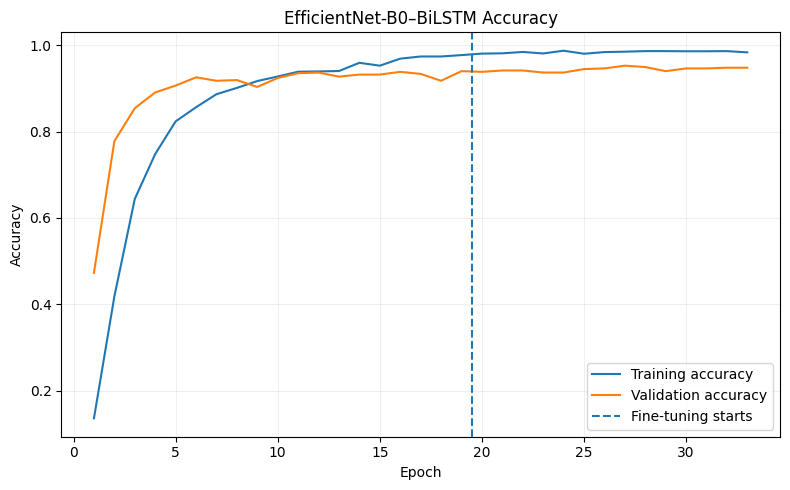

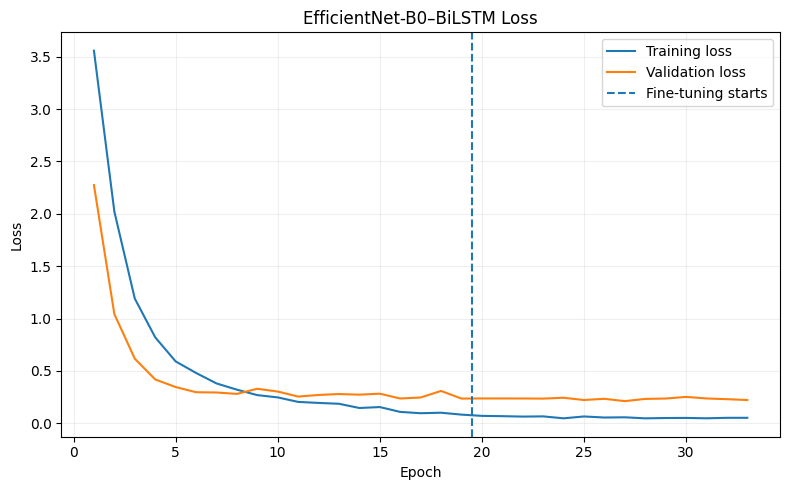

In [21]:
# ============================================================
# STEP 16 — ACTUAL SELECTED TRAINING PATH
# EfficientNet-B0–BiLSTM
# Frozen best checkpoint → Fine-tuning
# ============================================================

import matplotlib.pyplot as plt
import numpy as np


# BEST_FROZEN_EPOCH was already calculated in Step 15
# For this run, it should be 19.

print("Best frozen epoch:", BEST_FROZEN_EPOCH)


# Keep only frozen training history up to the selected checkpoint
train_acc = (
    history.history["accuracy"][:BEST_FROZEN_EPOCH]
    + fine_tune_history.history["accuracy"]
)

val_acc = (
    history.history["val_accuracy"][:BEST_FROZEN_EPOCH]
    + fine_tune_history.history["val_accuracy"]
)

train_loss = (
    history.history["loss"][:BEST_FROZEN_EPOCH]
    + fine_tune_history.history["loss"]
)

val_loss = (
    history.history["val_loss"][:BEST_FROZEN_EPOCH]
    + fine_tune_history.history["val_loss"]
)


epochs = np.arange(
    1,
    len(train_acc) + 1
)

fine_tune_start = (
    BEST_FROZEN_EPOCH + 0.5
)


# ============================================================
# ACCURACY
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    epochs,
    train_acc,
    label="Training accuracy"
)

plt.plot(
    epochs,
    val_acc,
    label="Validation accuracy"
)

plt.axvline(
    fine_tune_start,
    linestyle="--",
    linewidth=1.5,
    label="Fine-tuning starts"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")

plt.title(
    "EfficientNet-B0–BiLSTM Accuracy"
)

plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()


# ============================================================
# LOSS
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    epochs,
    train_loss,
    label="Training loss"
)

plt.plot(
    epochs,
    val_loss,
    label="Validation loss"
)

plt.axvline(
    fine_tune_start,
    linestyle="--",
    linewidth=1.5,
    label="Fine-tuning starts"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.title(
    "EfficientNet-B0–BiLSTM Loss"
)

plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

In [24]:
# ============================================================
# SELECT FINAL MODEL 3 CHECKPOINT
# ============================================================

SELECTED_CHECKPOINT = "fine-tuned"

SELECTED_CHECKPOINT_PATH = (
    FINE_TUNE_CHECKPOINT_PATH
)

print("Selected checkpoint:", SELECTED_CHECKPOINT)
print("Selected path:", SELECTED_CHECKPOINT_PATH)



Selected checkpoint: fine-tuned
Selected path: /content/baya_model3_output/Baybayin_EfficientNetB0_BiLSTM_finetuned_best_1.0.keras


In [25]:
best_model = tf.keras.models.load_model(
    SELECTED_CHECKPOINT_PATH
)

## Step 17 — Evaluate the best checkpoint on the untouched test export

In [26]:
# ============================================================
# STEP 17 — MODEL 3 FINAL TEST EVALUATION
# EfficientNet-B0–BiLSTM
# ============================================================

import numpy as np

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
)


# ============================================================
# LOAD SELECTED BEST MODEL
#
# Model selection was performed using validation loss
# BEFORE evaluating the untouched test set.
# ============================================================

best_model = tf.keras.models.load_model(
    SELECTED_CHECKPOINT_PATH
)

print("Loaded selected best Model 3:")
print(SELECTED_CHECKPOINT_PATH)
print("Selected checkpoint:", SELECTED_CHECKPOINT)


# ============================================================
# TEST-SET PREDICTIONS
# ============================================================

test_probs = best_model.predict(
    {
        "image_input": Ximg_test,
        "sequence_input": Xseq_test,
    },
    batch_size=BATCH_SIZE,
    verbose=1,
)

y_pred = np.argmax(
    test_probs,
    axis=1
)


# ============================================================
# OVERALL TEST METRICS
# ============================================================

accuracy = accuracy_score(
    y_test,
    y_pred
)

(
    macro_precision,
    macro_recall,
    macro_f1,
    _
) = precision_recall_fscore_support(
    y_test,
    y_pred,
    average="macro",
    zero_division=0,
)


# ============================================================
# PER-CLASS CLASSIFICATION REPORT
# ============================================================

report = classification_report(
    y_test,
    y_pred,
    labels=list(range(NUM_CLASSES)),
    target_names=[
        id_to_label[i]
        for i in range(NUM_CLASSES)
    ],
    output_dict=True,
    zero_division=0,
)

all_labels = [
    id_to_label[i]
    for i in range(NUM_CLASSES)
]


# ============================================================
# EXACT BAYA CLASS GROUPS
#
# 3 vowels
# 15 base consonants
# 15 A forms
# 15 E/I forms
# 15 O/U forms
#
# TOTAL = 63 classes
# ============================================================

vowels = [
    "a",
    "e_i",
    "o_u",
]


base_consonants = [
    "b",
    "d",
    "g",
    "h",
    "k",
    "l",
    "m",
    "n",
    "ng",
    "p",
    "r",
    "s",
    "t",
    "w",
    "y",
]


a_forms = [
    "ba",
    "da_ra",
    "ga",
    "ha",
    "ka",
    "la",
    "ma",
    "na",
    "nga",
    "pa",
    "ra",
    "sa",
    "ta",
    "wa",
    "ya",
]


ei_forms = [
    "be_bi",
    "de_di",
    "ge_gi",
    "he_hi",
    "ke_ki",
    "le_li",
    "me_mi",
    "ne_ni",
    "nge_ngi",
    "pe_pi",
    "re_ri",
    "se_si",
    "te_ti",
    "we_wi",
    "ye_yi",
]


ou_forms = [
    "bo_bu",
    "do_du",
    "go_gu",
    "ho_hu",
    "ko_ku",
    "lo_lu",
    "mo_mu",
    "no_nu",
    "ngo_ngu",
    "po_pu",
    "ro_ru",
    "so_su",
    "to_tu",
    "wo_wu",
    "yo_yu",
]


# ============================================================
# DISPLAY-FRIENDLY LABELS
#
# Only affects printed output.
# Does NOT modify actual dataset/model labels.
# ============================================================

display_names = {

    # Vowels
    "a": "a",
    "e_i": "e/i",
    "o_u": "o/u",

    # Base consonants
    "b": "b",
    "d": "d",
    "g": "g",
    "h": "h",
    "k": "k",
    "l": "l",
    "m": "m",
    "n": "n",
    "ng": "ng",
    "p": "p",
    "r": "r",
    "s": "s",
    "t": "t",
    "w": "w",
    "y": "y",

    # A forms
    "ba": "ba",
    "da_ra": "da/ra",
    "ga": "ga",
    "ha": "ha",
    "ka": "ka",
    "la": "la",
    "ma": "ma",
    "na": "na",
    "nga": "nga",
    "pa": "pa",
    "ra": "ra",
    "sa": "sa",
    "ta": "ta",
    "wa": "wa",
    "ya": "ya",

    # E/I forms
    "be_bi": "be/bi",
    "de_di": "de/di",
    "ge_gi": "ge/gi",
    "he_hi": "he/hi",
    "ke_ki": "ke/ki",
    "le_li": "le/li",
    "me_mi": "me/mi",
    "ne_ni": "ne/ni",
    "nge_ngi": "nge/ngi",
    "pe_pi": "pe/pi",
    "re_ri": "re/ri",
    "se_si": "se/si",
    "te_ti": "te/ti",
    "we_wi": "we/wi",
    "ye_yi": "ye/yi",

    # O/U forms
    "bo_bu": "bo/bu",
    "do_du": "do/du",
    "go_gu": "go/gu",
    "ho_hu": "ho/hu",
    "ko_ku": "ko/ku",
    "lo_lu": "lo/lu",
    "mo_mu": "mo/mu",
    "no_nu": "no/nu",
    "ngo_ngu": "ngo/ngu",
    "po_pu": "po/pu",
    "ro_ru": "ro/ru",
    "so_su": "so/su",
    "to_tu": "to/tu",
    "wo_wu": "wo/wu",
    "yo_yu": "yo/yu",
}


# ============================================================
# PRINT GROUP FUNCTION
# ============================================================

def print_group(title, labels):

    print("\n" + "=" * 82)
    print(title)
    print("=" * 82)

    print(
        f"{'Class':<20}"
        f"{'Precision':>12}"
        f"{'Recall':>12}"
        f"{'F1-score':>12}"
        f"{'Support':>10}"
    )

    print("-" * 82)

    precisions = []
    recalls = []
    f1_scores = []
    supports = []

    for label in labels:

        if label not in report:

            print(
                f"WARNING: {label} not found "
                "in classification report."
            )

            continue

        values = report[label]

        precision = values["precision"]
        recall = values["recall"]
        f1 = values["f1-score"]
        support = int(
            values["support"]
        )

        precisions.append(
            precision
        )

        recalls.append(
            recall
        )

        f1_scores.append(
            f1
        )

        supports.append(
            support
        )

        shown_label = display_names.get(
            label,
            label
        )

        print(
            f"{shown_label:<20}"
            f"{precision:>12.4f}"
            f"{recall:>12.4f}"
            f"{f1:>12.4f}"
            f"{support:>10}"
        )

    if precisions:

        print("-" * 82)

        print(
            f"{'GROUP AVG':<20}"
            f"{np.mean(precisions):>12.4f}"
            f"{np.mean(recalls):>12.4f}"
            f"{np.mean(f1_scores):>12.4f}"
            f"{sum(supports):>10}"
        )


# ============================================================
# OVERALL MODEL 3 RESULTS
# ============================================================

print("\n" + "=" * 72)

print(
    "MODEL 3 — EFFICIENTNET-B0–BiLSTM "
    "TEST RESULTS"
)

print("=" * 72)


print(
    f"Accuracy:        "
    f"{accuracy:.4f} "
    f"({accuracy * 100:.2f}%)"
)

print(
    f"Macro Precision: "
    f"{macro_precision:.4f} "
    f"({macro_precision * 100:.2f}%)"
)

print(
    f"Macro Recall:    "
    f"{macro_recall:.4f} "
    f"({macro_recall * 100:.2f}%)"
)

print(
    f"Macro F1:        "
    f"{macro_f1:.4f} "
    f"({macro_f1 * 100:.2f}%)"
)


# ============================================================
# ORGANIZED CLASSIFICATION REPORT
# ============================================================

print_group(
    "1. VOWELS",
    vowels
)

print_group(
    "2. BASE CONSONANTS",
    base_consonants
)

print_group(
    "3. CONSONANTS — A FORM",
    a_forms
)

print_group(
    "4. CONSONANTS — E/I FORM",
    ei_forms
)

print_group(
    "5. CONSONANTS — O/U FORM",
    ou_forms
)


# ============================================================
# VERIFY ALL 63 CLASSES
# ============================================================

grouped_labels = (
    vowels
    + base_consonants
    + a_forms
    + ei_forms
    + ou_forms
)


missing_labels = sorted(
    set(all_labels)
    - set(grouped_labels)
)

extra_labels = sorted(
    set(grouped_labels)
    - set(all_labels)
)

duplicate_labels = sorted(
    {
        label
        for label in grouped_labels
        if grouped_labels.count(label) > 1
    }
)


# ============================================================
# GROUPING CHECK
# ============================================================

print("\n" + "=" * 65)
print("GROUPING CHECK")
print("=" * 65)


print(
    f"Vowels:            "
    f"{len(vowels)}"
)

print(
    f"Base consonants:   "
    f"{len(base_consonants)}"
)

print(
    f"A forms:           "
    f"{len(a_forms)}"
)

print(
    f"E/I forms:         "
    f"{len(ei_forms)}"
)

print(
    f"O/U forms:         "
    f"{len(ou_forms)}"
)


print("-" * 65)


print(
    f"Total grouped:     "
    f"{len(grouped_labels)}"
)

print(
    f"Expected classes:  "
    f"{NUM_CLASSES}"
)

print(
    f"Missing labels:    "
    f"{len(missing_labels)}"
)

print(
    f"Extra labels:      "
    f"{len(extra_labels)}"
)

print(
    f"Duplicates:        "
    f"{len(duplicate_labels)}"
)


# ============================================================
# PRINT ANY GROUPING PROBLEMS
# ============================================================

if missing_labels:

    print("\nMissing labels:")

    for label in missing_labels:
        print(
            " -",
            repr(label)
        )


if extra_labels:

    print("\nExtra labels:")

    for label in extra_labels:
        print(
            " -",
            repr(label)
        )


if duplicate_labels:

    print("\nDuplicate labels:")

    for label in duplicate_labels:
        print(
            " -",
            repr(label)
        )


# ============================================================
# FINAL GROUPING VALIDATION
# ============================================================

if (
    len(grouped_labels) == NUM_CLASSES
    and len(missing_labels) == 0
    and len(extra_labels) == 0
    and len(duplicate_labels) == 0
):

    print(
        "\n✓ All 63 classes are "
        "correctly grouped exactly once."
    )

else:

    print(
        "\n⚠ Check class grouping "
        "before using the report."
    )

Loaded selected best Model 3:
/content/baya_model3_output/Baybayin_EfficientNetB0_BiLSTM_finetuned_best_1.0.keras
Selected checkpoint: fine-tuned
20/20 ━━━━━━━━━━━━━━━━━━━━ 5s 144ms/step

MODEL 3 — EFFICIENTNET-B0–BiLSTM TEST RESULTS
Accuracy:        0.9810 (98.10%)
Macro Precision: 0.9833 (98.33%)
Macro Recall:    0.9810 (98.10%)
Macro F1:        0.9810 (98.10%)

1. VOWELS
Class                  Precision      Recall    F1-score   Support
----------------------------------------------------------------------------------
a                         1.0000      1.0000      1.0000        10
e/i                       1.0000      1.0000      1.0000        10
o/u                       1.0000      1.0000      1.0000        10
----------------------------------------------------------------------------------
GROUP AVG                 1.0000      1.0000      1.0000        30

2. BASE CONSONANTS
Class                  Precision      Recall    F1-score   Support
-----------------------------------

## Step 18 — Confusion matrix

In [27]:
# ============================================================
# STEP 18 — MODEL 2 SEPARATE CONFUSION MATRICES
# MobileNetV3-Small–BiLSTM
# ============================================================

import numpy as np
import matplotlib.pyplot as plt


# ============================================================
# LABEL → NUMERIC CLASS ID
# ============================================================

label_to_id = {
    id_to_label[i]: i
    for i in range(NUM_CLASSES)
}


# ============================================================
# FUNCTION FOR ONE GROUP
# ============================================================

def plot_group_confusion_matrix(
    title,
    group_labels,
    normalized=False
):

    """
    Confusion matrix for samples whose TRUE class belongs
    to the selected character group.

    Predictions outside the selected group are placed
    in an 'Other' column so cross-group errors are retained.
    """

    # --------------------------------------------------------
    # Numeric class IDs
    # --------------------------------------------------------

    group_ids = [
        label_to_id[label]
        for label in group_labels
    ]


    # --------------------------------------------------------
    # Select samples whose TRUE class belongs to this group
    # --------------------------------------------------------

    y_test_np = np.asarray(y_test)
    y_pred_np = np.asarray(y_pred)

    mask = np.isin(
        y_test_np,
        group_ids
    )

    y_true_group = y_test_np[mask]
    y_pred_group = y_pred_np[mask]

    n = len(group_labels)


    # --------------------------------------------------------
    # Matrix:
    #
    # rows    = true classes
    # columns = group predictions + Other
    # --------------------------------------------------------

    cm_group = np.zeros(
        (
            n,
            n + 1
        ),
        dtype=np.int32
    )


    # Class ID → position within group
    id_to_position = {
        class_id: position
        for position, class_id
        in enumerate(group_ids)
    }


    # --------------------------------------------------------
    # Fill matrix
    # --------------------------------------------------------

    for true_id, pred_id in zip(
        y_true_group,
        y_pred_group
    ):

        true_id = int(true_id)
        pred_id = int(pred_id)

        row = id_to_position[
            true_id
        ]

        if pred_id in id_to_position:

            col = id_to_position[
                pred_id
            ]

        else:

            # Prediction belongs to another character group
            col = n

        cm_group[row, col] += 1


    # ========================================================
    # OPTIONAL NORMALIZATION
    # ========================================================

    if normalized:

        row_sums = cm_group.sum(
            axis=1,
            keepdims=True
        )

        matrix_to_plot = np.divide(
            cm_group,
            row_sums,
            out=np.zeros_like(
                cm_group,
                dtype=float
            ),
            where=row_sums != 0
        )

        colorbar_label = "Proportion"

    else:

        matrix_to_plot = cm_group

        colorbar_label = "Number of Samples"


    # ========================================================
    # DISPLAY LABELS
    # ========================================================

    true_names = [
        display_names.get(
            label,
            label
        )
        for label in group_labels
    ]

    predicted_names = (
        true_names
        + ["Other"]
    )


    # ========================================================
    # FIGURE SIZE
    # ========================================================

    width = max(
        7,
        (n + 1) * 0.65
    )

    height = max(
        5,
        n * 0.55
    )


    # ========================================================
    # PLOT
    # ========================================================

    fig, ax = plt.subplots(
        figsize=(
            width,
            height
        )
    )

    im = ax.imshow(
        matrix_to_plot,
        interpolation="nearest",
        aspect="auto",
        cmap="Blues"
    )


    ax.set_title(
        title,
        fontsize=14,
        pad=15
    )

    ax.set_xlabel(
        "Predicted Class",
        fontsize=11
    )

    ax.set_ylabel(
        "True Class",
        fontsize=11
    )


    # --------------------------------------------------------
    # X-axis
    # --------------------------------------------------------

    ax.set_xticks(
        np.arange(n + 1)
    )

    ax.set_xticklabels(
        predicted_names,
        rotation=90,
        fontsize=9
    )


    # --------------------------------------------------------
    # Y-axis
    # --------------------------------------------------------

    ax.set_yticks(
        np.arange(n)
    )

    ax.set_yticklabels(
        true_names,
        fontsize=9
    )


    # --------------------------------------------------------
    # Colorbar
    # --------------------------------------------------------

    fig.colorbar(
        im,
        ax=ax,
        fraction=0.046,
        pad=0.04,
        label=colorbar_label
    )


    # ========================================================
    # CELL VALUES
    # ========================================================

    max_value = (
        matrix_to_plot.max()
        if matrix_to_plot.size > 0
        else 0
    )

    threshold = (
        max_value * 0.50
    )


    for i in range(n):

        for j in range(n + 1):

            value = matrix_to_plot[
                i,
                j
            ]

            if normalized:

                text = (
                    f"{value:.2f}"
                    if value > 0
                    else ""
                )

            else:

                text = (
                    str(int(value))
                    if value > 0
                    else ""
                )

            if text:

                text_color = (
                    "white"
                    if value >= threshold
                    else "black"
                )

                ax.text(
                    j,
                    i,
                    text,
                    ha="center",
                    va="center",
                    fontsize=8,
                    color=text_color,
                    fontweight="bold"
                )


    # ========================================================
    # GRID
    # ========================================================

    ax.set_xticks(
        np.arange(
            -0.5,
            n + 1,
            1
        ),
        minor=True
    )

    ax.set_yticks(
        np.arange(
            -0.5,
            n,
            1
        ),
        minor=True
    )

    ax.grid(
        which="minor",
        linestyle="-",
        linewidth=0.3,
        alpha=0.3
    )

    ax.tick_params(
        which="minor",
        bottom=False,
        left=False
    )


    plt.tight_layout()
    plt.show()


    # ========================================================
    # GROUP STATISTICS
    # ========================================================

    total_samples = cm_group.sum()

    correct_predictions = sum(
        cm_group[i, i]
        for i in range(n)
    )

    cross_group_errors = (
        cm_group[:, -1].sum()
    )

    group_accuracy = (
        correct_predictions
        / total_samples
        if total_samples > 0
        else 0
    )


    print(
        f"\n{title}"
    )

    print(
        f"Samples: {total_samples}"
    )

    print(
        f"Correct predictions: "
        f"{correct_predictions}"
    )

    print(
        f"Cross-group errors: "
        f"{cross_group_errors}"
    )

    print(
        f"Group accuracy: "
        f"{group_accuracy:.4f} "
        f"({group_accuracy * 100:.2f}%)"
    )

    print("-" * 60)


    return cm_group

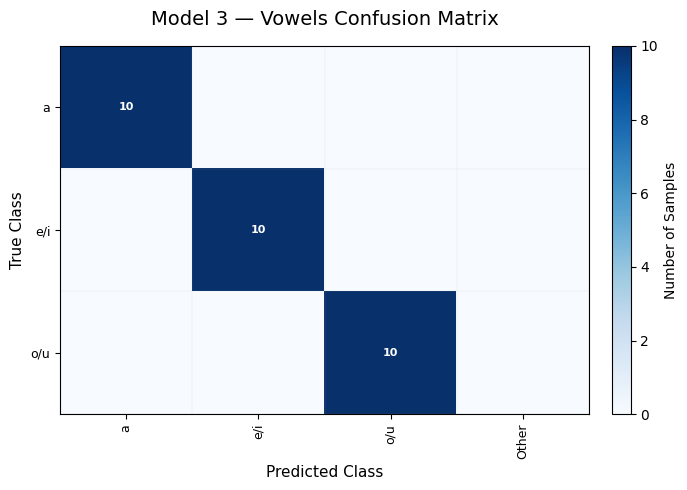


Model 3 — Vowels Confusion Matrix
Samples: 30
Correct predictions: 30
Cross-group errors: 0
Group accuracy: 1.0000 (100.00%)
------------------------------------------------------------


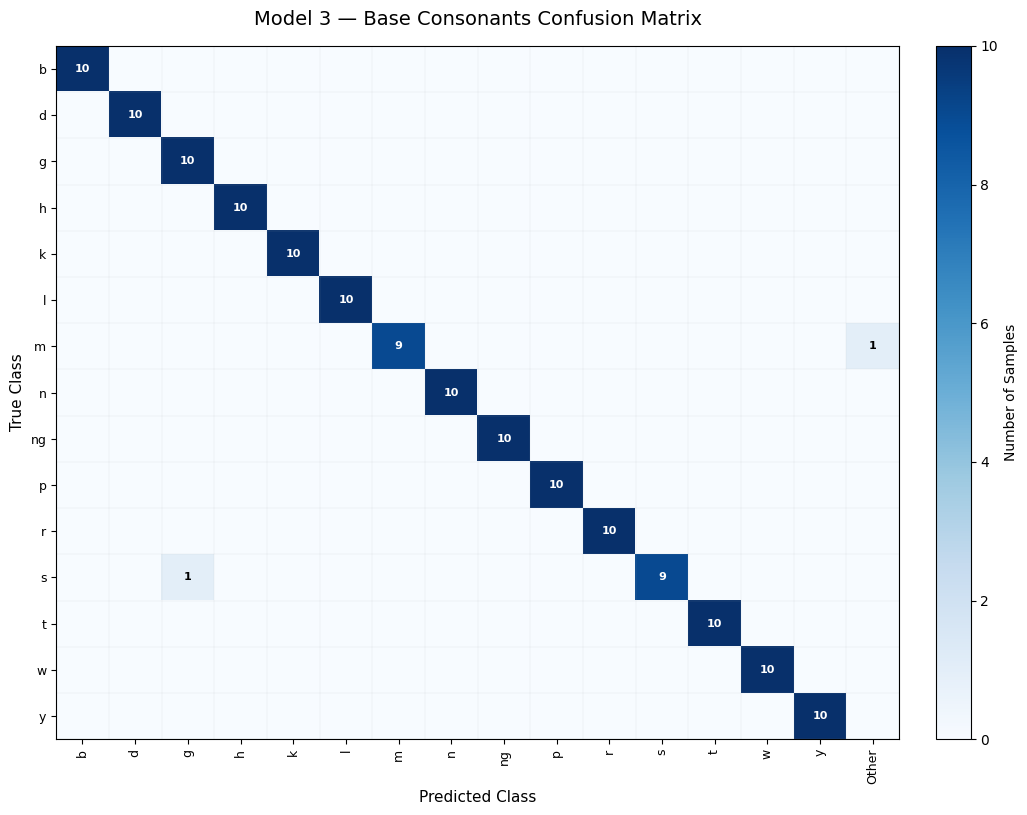


Model 3 — Base Consonants Confusion Matrix
Samples: 150
Correct predictions: 148
Cross-group errors: 1
Group accuracy: 0.9867 (98.67%)
------------------------------------------------------------


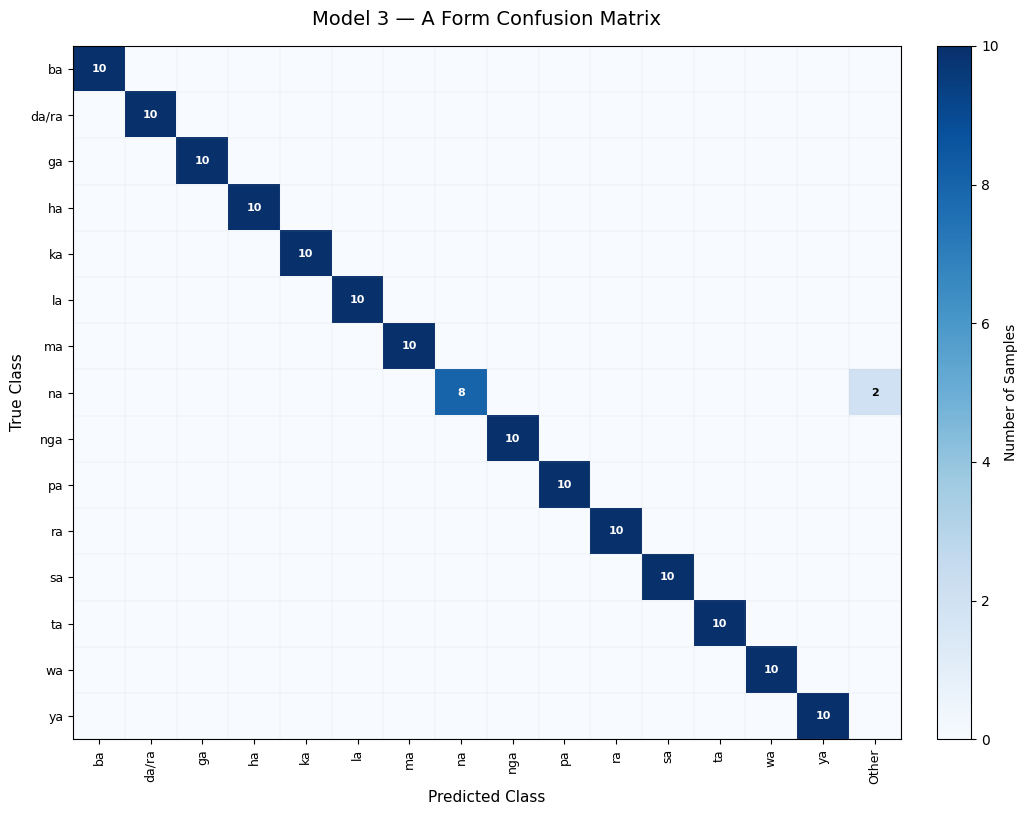


Model 3 — A Form Confusion Matrix
Samples: 150
Correct predictions: 148
Cross-group errors: 2
Group accuracy: 0.9867 (98.67%)
------------------------------------------------------------


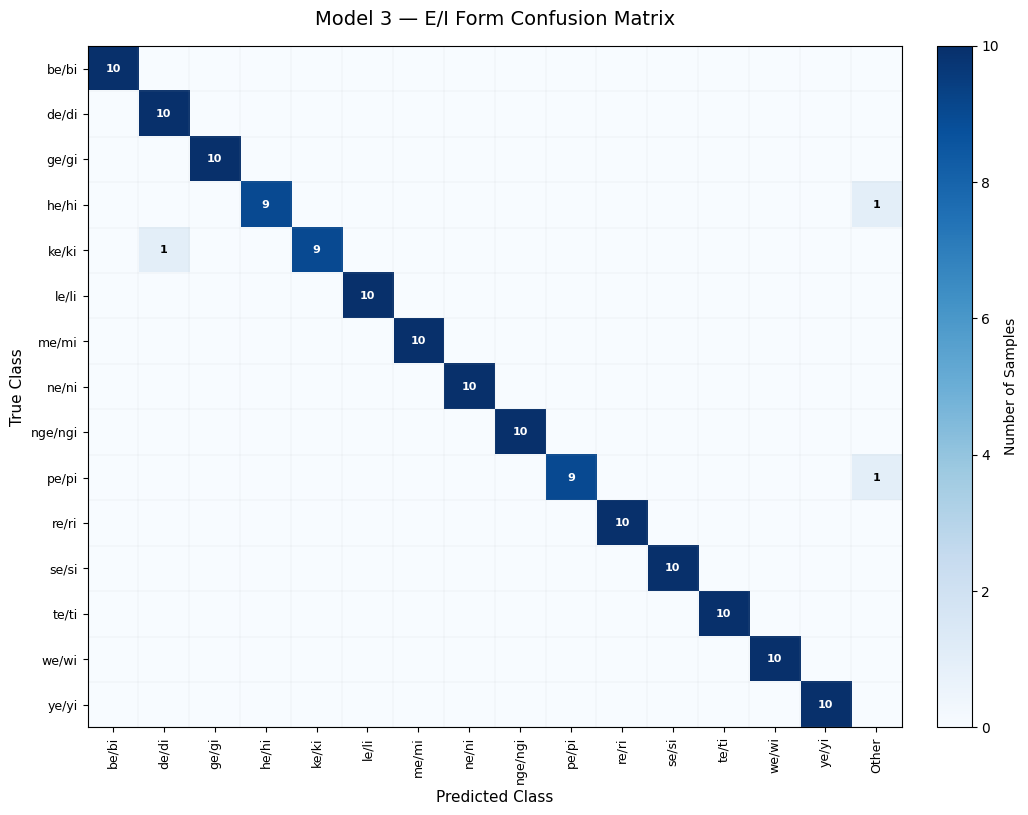


Model 3 — E/I Form Confusion Matrix
Samples: 150
Correct predictions: 147
Cross-group errors: 2
Group accuracy: 0.9800 (98.00%)
------------------------------------------------------------


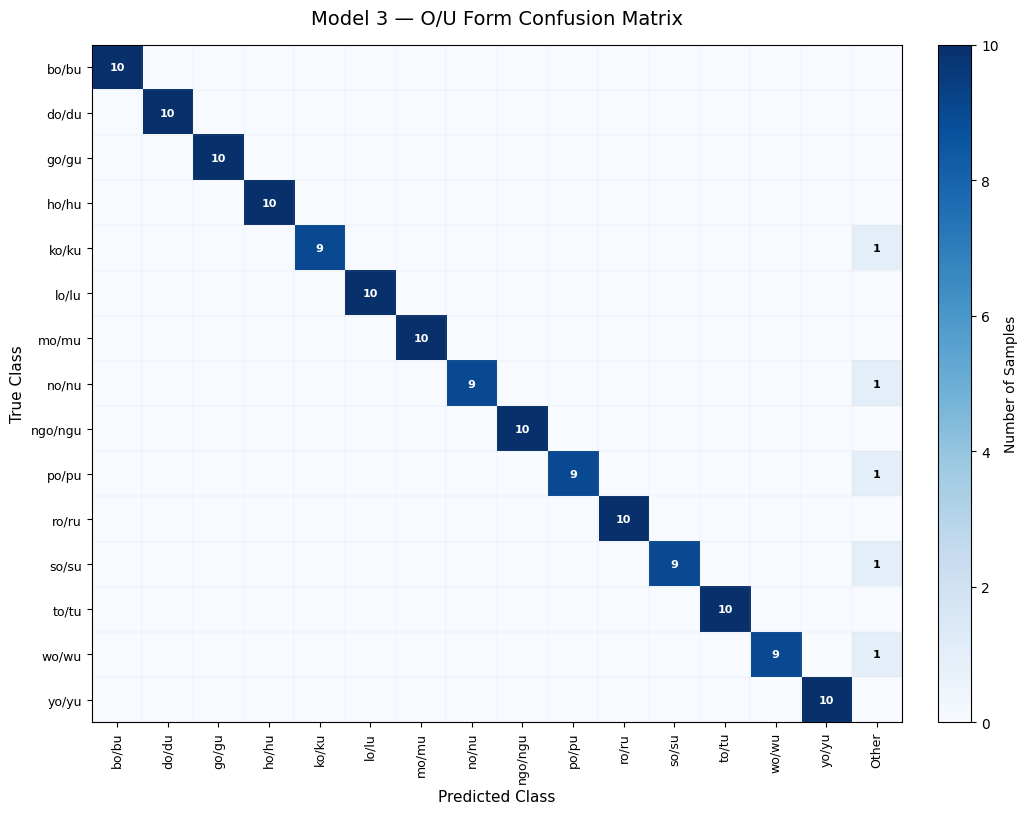


Model 3 — O/U Form Confusion Matrix
Samples: 150
Correct predictions: 145
Cross-group errors: 5
Group accuracy: 0.9667 (96.67%)
------------------------------------------------------------

MODEL 3 — SEPARATE CONFUSION MATRICES COMPLETE
Generated matrices:
1. Vowels
2. Base Consonants
3. A Forms
4. E/I Forms
5. O/U Forms


In [36]:
# ============================================================
# 1. VOWELS
# ============================================================

cm_vowels = plot_group_confusion_matrix(
    title=(
        "Model 3 — Vowels Confusion Matrix"
    ),
    group_labels=vowels,
    normalized=False
)


# ============================================================
# 2. BASE CONSONANTS
# ============================================================

cm_base_consonants = plot_group_confusion_matrix(
    title=(
        "Model 3 — Base Consonants Confusion Matrix"
    ),
    group_labels=base_consonants,
    normalized=False
)


# ============================================================
# 3. A FORMS
# ============================================================

cm_a_forms = plot_group_confusion_matrix(
    title=(
        "Model 3 — A Form Confusion Matrix"
    ),
    group_labels=a_forms,
    normalized=False
)


# ============================================================
# 4. E/I FORMS
# ============================================================

cm_ei_forms = plot_group_confusion_matrix(
    title=(
        "Model 3 — E/I Form Confusion Matrix"
    ),
    group_labels=ei_forms,
    normalized=False
)


# ============================================================
# 5. O/U FORMS
# ============================================================

cm_ou_forms = plot_group_confusion_matrix(
    title=(
        "Model 3 — O/U Form Confusion Matrix"
    ),
    group_labels=ou_forms,
    normalized=False
)


# ============================================================
# COMPLETE
# ============================================================

print("\n" + "=" * 65)
print(
    "MODEL 3 — SEPARATE CONFUSION MATRICES COMPLETE"
)
print("=" * 65)

print("Generated matrices:")
print("1. Vowels")
print("2. Base Consonants")
print("3. A Forms")
print("4. E/I Forms")
print("5. O/U Forms")

## Step 19 — Measure inference time

In [29]:
# ============================================================
# STEP 19 — MODEL 3 SINGLE-SAMPLE INFERENCE LATENCY
# EfficientNet-B0–BiLSTM
# ============================================================

import time
import numpy as np


# ============================================================
# WARM-UP
# ============================================================

for _ in range(10):

    _ = best_model.predict(
        {
            "image_input": Ximg_test[:1],
            "sequence_input": Xseq_test[:1],
        },
        verbose=0,
    )


# ============================================================
# TIME SINGLE-SAMPLE INFERENCE
# ============================================================

timings_ms = []

n_timing = min(
    100,
    len(y_test)
)


for i in range(n_timing):

    start = time.perf_counter()

    _ = best_model.predict(
        {
            "image_input": Ximg_test[i:i+1],
            "sequence_input": Xseq_test[i:i+1],
        },
        verbose=0,
    )

    end = time.perf_counter()

    timings_ms.append(
        (end - start) * 1000
    )


# ============================================================
# SUMMARY
# ============================================================

mean_inference_ms = float(
    np.mean(timings_ms)
)

median_inference_ms = float(
    np.median(timings_ms)
)

std_inference_ms = float(
    np.std(timings_ms)
)

p95_inference_ms = float(
    np.percentile(
        timings_ms,
        95
    )
)


print("\n" + "=" * 65)
print("MODEL 3 — INFERENCE LATENCY")
print("=" * 65)

print(
    f"Samples timed:                  "
    f"{n_timing}"
)

print(
    f"Mean single-sample inference:   "
    f"{mean_inference_ms:.2f} ms"
)

print(
    f"Median single-sample inference: "
    f"{median_inference_ms:.2f} ms"
)

print(
    f"Std. deviation:                 "
    f"{std_inference_ms:.2f} ms"
)

print(
    f"95th percentile:                "
    f"{p95_inference_ms:.2f} ms"
)


MODEL 3 — INFERENCE LATENCY
Samples timed:                  100
Mean single-sample inference:   104.07 ms
Median single-sample inference: 97.08 ms
Std. deviation:                 19.10 ms
95th percentile:                137.14 ms


## Step 20 — Save the final model, label mapping, preprocessing configuration, and metrics

In [31]:
# ============================================================
# CREATE FINE-TUNING SUMMARY VARIABLES
# Required before Step 20
# ============================================================

import numpy as np


BEST_FINETUNED_EPOCH = (
    int(
        np.argmin(
            fine_tune_history.history["val_loss"]
        )
    )
    + 1
)


BEST_FINETUNED_VAL_LOSS = float(
    fine_tune_history.history["val_loss"][
        BEST_FINETUNED_EPOCH - 1
    ]
)


BEST_FINETUNED_VAL_ACCURACY = float(
    fine_tune_history.history["val_accuracy"][
        BEST_FINETUNED_EPOCH - 1
    ]
)


print("=" * 60)
print("BEST FINE-TUNED MODEL")
print("=" * 60)

print(
    f"Best fine-tuned epoch: "
    f"{BEST_FINETUNED_EPOCH}"
)

print(
    f"Best fine-tuned val_loss: "
    f"{BEST_FINETUNED_VAL_LOSS:.5f}"
)

print(
    f"Validation accuracy: "
    f"{BEST_FINETUNED_VAL_ACCURACY:.4f} "
    f"({BEST_FINETUNED_VAL_ACCURACY * 100:.2f}%)"
)

BEST FINE-TUNED MODEL
Best fine-tuned epoch: 8
Best fine-tuned val_loss: 0.21195
Validation accuracy: 0.9524 (95.24%)


In [32]:
BEST_FROZEN_EPOCH = (
    int(
        np.argmin(
            history.history["val_loss"]
        )
    )
    + 1
)

BEST_FROZEN_VAL_LOSS = float(
    history.history["val_loss"][
        BEST_FROZEN_EPOCH - 1
    ]
)

BEST_FROZEN_VAL_ACCURACY = float(
    history.history["val_accuracy"][
        BEST_FROZEN_EPOCH - 1
    ]
)

In [33]:
if BEST_FINETUNED_VAL_LOSS < BEST_FROZEN_VAL_LOSS:

    SELECTED_CHECKPOINT = "fine-tuned"
    SELECTED_CHECKPOINT_PATH = FINE_TUNE_CHECKPOINT_PATH

else:

    SELECTED_CHECKPOINT = "frozen"
    SELECTED_CHECKPOINT_PATH = FROZEN_CHECKPOINT_PATH


print("Selected checkpoint:", SELECTED_CHECKPOINT)
print("Selected path:", SELECTED_CHECKPOINT_PATH)

Selected checkpoint: fine-tuned
Selected path: /content/baya_model3_output/Baybayin_EfficientNetB0_BiLSTM_finetuned_best_1.0.keras


In [34]:
# ============================================================
# STEP 20 — SAVE FINAL MODEL 3 ARTIFACTS
# EfficientNet-B0–BiLSTM
# ============================================================

import json


# ============================================================
# SAVE FINAL KERAS MODEL
# ============================================================

best_model.save(
    FINAL_MODEL_PATH
)


# ============================================================
# SAVE LABEL MAPPING
# ============================================================

label_mapping_path = (
    OUTPUT_DIR /
    f"{MODEL_NAME}_labels_{MODEL_VERSION}.json"
)

with open(
    label_mapping_path,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        {
            "label_to_id": label_to_id,

            "id_to_label": {
                str(k): v
                for k, v
                in id_to_label.items()
            },
        },
        f,
        ensure_ascii=False,
        indent=2,
    )


# ============================================================
# SAVE PREPROCESSING CONFIGURATION
# ============================================================

preprocess_path = (
    OUTPUT_DIR /
    f"{MODEL_NAME}_preprocessing_{MODEL_VERSION}.json"
)

with open(
    preprocess_path,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        {
            # ------------------------------------------------
            # IMAGE INPUT
            # ------------------------------------------------

            "image_height":
                IMG_HEIGHT,

            "image_width":
                IMG_WIDTH,

            "image_channels":
                IMG_CHANNELS,

            "image_background_rule":
                "white background mapped to approximately 0 "
                "and black ink to high values",

            "image_position_scale_normalization":
                "ink bounding box -> 15% padding -> "
                "centered square -> resize to 96x96",


            # ------------------------------------------------
            # EFFICIENTNET-B0 INPUT
            # ------------------------------------------------

            "efficientnet_input_conversion":
                "single-channel grayscale repeated to "
                "3 RGB channels",

            "efficientnet_input_scale":
                "preprocessed image values 0-1 multiplied "
                "by 255 before EfficientNet-B0 built-in "
                "input rescaling",

            "efficientnet_builtin_preprocessing":
                True,


            # ------------------------------------------------
            # STROKE SEQUENCE INPUT
            # ------------------------------------------------

            "max_sequence_length":
                MAX_SEQ_LEN,

            "sequence_features": [
                "x_shape",
                "y_shape",
                "dx",
                "dy",
                "dt_norm",
                "stroke_start",
            ],

            "trajectory_position_scale_normalization":
                "trajectory bounding box -> centered square "
                "using max(width,height) with 15% padding",

            "sequence_overflow_rule":
                "stroke-preserving proportional downsampling",


            # ------------------------------------------------
            # DATA SPLIT
            # ------------------------------------------------

            "group_split": {
                "train_exports":
                    train_groups,

                "validation_exports":
                    val_groups,

                "test_exports":
                    test_groups,
            },
        },
        f,
        indent=2,
    )


# ============================================================
# MODEL SIZE
# ============================================================

model_size_mb = (
    FINAL_MODEL_PATH.stat().st_size
    / (1024 * 1024)
)


# ============================================================
# SAVE MODEL 3 METRICS
# ============================================================

metrics = {

    # --------------------------------------------------------
    # MODEL IDENTIFICATION
    # --------------------------------------------------------

    "model":
        "EfficientNet-B0-BiLSTM",

    "version":
        MODEL_VERSION,

    "visual_backbone":
        "EfficientNet-B0",

    "sequence_backbone":
        "Bidirectional LSTM (64 units per direction)",

    "pretrained_weights":
        "ImageNet",

    "transfer_learning":
        True,

    "fine_tuning_attempted":
        True,

    "fine_tuned_backbone_layers":
        20,

    "initial_fine_tuning_learning_rate":
        1e-5,


    # --------------------------------------------------------
    # TEST PERFORMANCE
    # --------------------------------------------------------

    "accuracy":
        float(accuracy),

    "macro_precision":
        float(macro_precision),

    "macro_recall":
        float(macro_recall),

    "macro_f1":
        float(macro_f1),


    # --------------------------------------------------------
    # INFERENCE LATENCY
    # --------------------------------------------------------

    "mean_inference_ms_colab":
        float(mean_inference_ms),

    "median_inference_ms_colab":
        float(median_inference_ms),

    "std_inference_ms_colab":
        float(std_inference_ms),

    "p95_inference_ms_colab":
        float(p95_inference_ms),


    # --------------------------------------------------------
    # MODEL SIZE
    # --------------------------------------------------------

    "model_size_mb":
        float(model_size_mb),


    # --------------------------------------------------------
    # DATASET INFORMATION
    # --------------------------------------------------------

    "num_classes":
        int(NUM_CLASSES),

    "train_samples":
        int(len(y_train)),

    "validation_samples":
        int(len(y_val)),

    "test_samples":
        int(len(y_test)),


    # --------------------------------------------------------
    # VALIDATION-BASED CHECKPOINT SELECTION
    # --------------------------------------------------------

    "selected_checkpoint":
        SELECTED_CHECKPOINT,

    "best_frozen_epoch":
        int(BEST_FROZEN_EPOCH),

    "best_frozen_val_loss":
        float(BEST_FROZEN_VAL_LOSS),

    "best_frozen_val_accuracy":
        float(BEST_FROZEN_VAL_ACCURACY),

    "best_finetuned_epoch":
        int(BEST_FINETUNED_EPOCH),

    "best_finetuned_val_loss":
        float(BEST_FINETUNED_VAL_LOSS),

    "best_finetuned_val_accuracy":
        float(BEST_FINETUNED_VAL_ACCURACY),
}


# ============================================================
# SAVE METRICS JSON
# ============================================================

metrics_path = (
    OUTPUT_DIR /
    f"{MODEL_NAME}_metrics_{MODEL_VERSION}.json"
)

with open(
    metrics_path,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        metrics,
        f,
        indent=2,
    )


# ============================================================
# PRINT SAVED FILES
# ============================================================

print("\n" + "=" * 70)
print("MODEL 3 — SAVED ARTIFACTS")
print("=" * 70)

for p in sorted(
    OUTPUT_DIR.iterdir()
):

    print(
        " -",
        p.name
    )


print(
    f"\nFinal model size: "
    f"{model_size_mb:.2f} MB"
)


print(
    f"Selected checkpoint: "
    f"{SELECTED_CHECKPOINT}"
)

print(
    f"Best frozen validation loss: "
    f"{BEST_FROZEN_VAL_LOSS:.5f}"
)

print(
    f"Best fine-tuned validation loss: "
    f"{BEST_FINETUNED_VAL_LOSS:.5f}"
)


MODEL 3 — SAVED ARTIFACTS
 - Baybayin_EfficientNetB0_BiLSTM_1.0.keras
 - Baybayin_EfficientNetB0_BiLSTM_cp_1.0.keras
 - Baybayin_EfficientNetB0_BiLSTM_finetuned_best_1.0.keras
 - Baybayin_EfficientNetB0_BiLSTM_frozen_best_1.0.keras
 - Baybayin_EfficientNetB0_BiLSTM_labels_1.0.json
 - Baybayin_EfficientNetB0_BiLSTM_metrics_1.0.json
 - Baybayin_EfficientNetB0_BiLSTM_preprocessing_1.0.json

Final model size: 27.81 MB
Selected checkpoint: fine-tuned
Best frozen validation loss: 0.23636
Best fine-tuned validation loss: 0.21195


In [35]:
from google.colab import files

archive_base = Path("/content") / f"{MODEL_NAME}_{MODEL_VERSION}_artifacts"
archive_path = shutil.make_archive(
    str(archive_base),
    "zip",
    root_dir=OUTPUT_DIR,
)

print("Created:", archive_path)
files.download(archive_path)

Created: /content/Baybayin_EfficientNetB0_BiLSTM_1.0_artifacts.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>